In [1]:
%store -r

In [2]:
### load libraries

### folder/file management
import os
import pathlib

### tabular data
import pandas as pd

### handle geospatial vector data
import geopandas as gpd

In [3]:
# subset Shirley Chisholm State Park from the New York State Parks shapefile
SCSP_gdf = NYSParks_gdf.loc[NYSParks_gdf.Name == "Shirley Chisholm"].dissolve()
SCSP_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,created_us,created_da,last_edite,last_edi_1,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,NYS.Parks.Admin,1661261121661,Rebecca.Newell@parks.ny.gov_nysparks,1773416839889,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None


In [4]:
### join the gbif observations to the Shirley Chisholm State Park polygon
gbif_scsp_gdf = (
    SCSP_gdf
       
    ### match the CRS of the gbif data and the ecoregions
    .to_crs(gbif_gdf.crs)

    ### find ecoregion for each observation
    .sjoin(
        gbif_gdf,
        how = 'inner', 
        predicate = 'contains')

   )

### check it out
gbif_scsp_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3989,2023,11,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,3595,2023,10,3.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5722,2021,1,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,436,2023,10,12.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1058,2025,10,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2016,2025,4,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5890,2021,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6097,2021,11,16.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6223,2021,10,10.0


<Axes: >

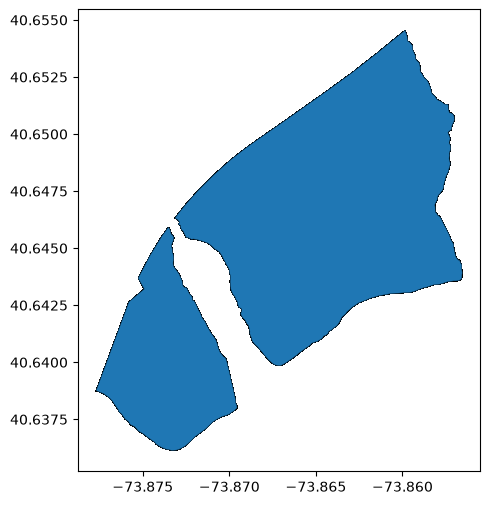

In [6]:
gbif_scsp_gdf.plot(figsize = (10, 6), edgecolor = "black", linewidth = 0.2)
# plt.show()

In [19]:
### Extract breeding months, June, July, August
### Since it is a geodataframe rather than dataframe use .isin instead of ==
breeding_gdf = gbif_scsp_gdf[gbif_scsp_gdf['month'].isin([6, 7, 8])]
breeding_gdf

,geometry,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5716,2021,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5474,2022,8,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5961,2021,6,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6266,2021,6,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1118,2021,7,4.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1125,2022,6,15.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4681,2022,8,2.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2239,2021,7,9.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4960,2022,7,1.0
0,"MULTIPOLYGON (((-73.87332 40.64558, -73.8733 4...",1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,186,2021,7,1.0


In [20]:
### making interactive plots of tabular and vector data
import hvplot.pandas

### customize the dynamic plot
import panel as pn

### make dynamic plot with geodataframe
import holoviews as hv

import matplotlib.pyplot as plt

In [ ]:
### Convert breeding to dataframe for plotting purposes
breeding_df = pd.DataFrame(breeding_gdf.drop(columns="geometry"))
breeding_df

,OBJECTID,UID,Name,Category,Label,Descriptio,Region,County,Source,Original,...,GlobalID,Shape__Are,Shape__Len,FacilityAb,RegionLabe,DrupalID,index_right,year,month,individualCount
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5716,2021,7,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5474,2022,8,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,5961,2021,6,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,6266,2021,6,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1118,2021,7,4.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,1125,2022,6,15.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4681,2022,8,2.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,2239,2021,7,9.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,4960,2022,7,1.0
0,1003,NaN,Shirley Chisholm,State Park,Shirley Chisholm State Park,NaN,12,Kings,Tax,2019,...,c616d7bd-ef82-4589-8269-f0d061a364dd,392812.488281,2763.368643,SCSP,Long Island,None,186,2021,7,1.0


<Axes: title={'center': 'Savannah Sparrow (Passerculus sandwichensis) counts during breeding season'}, xlabel='Year', ylabel='Number of individuals'>

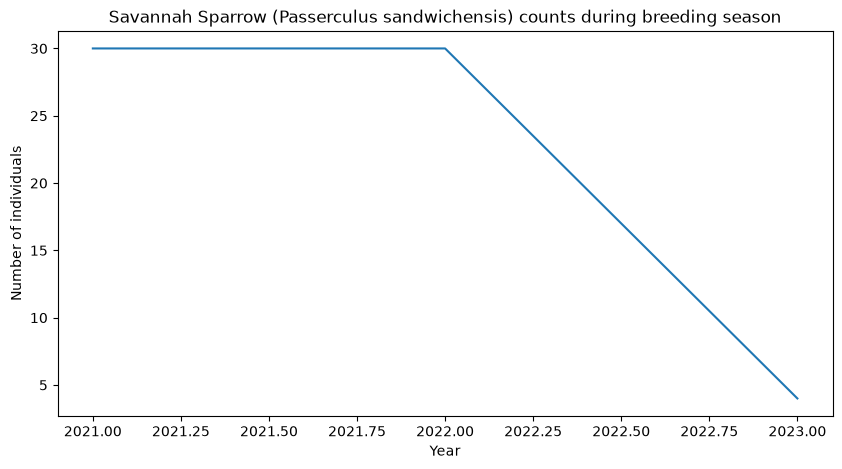

In [28]:
### Plot sparrow count progression during breeding seasons 2021 - 2025
# gdf.sort_values("Year").hvplot.line(
#     x="Year", 
#     y="Number of individuals", 
#     by="site_id",  # <-- Replace with your location/transect column name
#     title="Savannah Sparrow counts by site"
# )
# breeding_df.plot(
#     legend = False,
#     x = "year", 
#     y = "individualCount",
#     xlabel = 'Year',
#     ylabel = 'Number of individuals',
#     figsize = (10, 5),
#     title = "Savannah Sparrow (Passerculus sandwichensis) counts during breeding season"    
# )

(
    breeding_df
    .groupby("year")["individualCount"]
    .sum()  # or .mean()
    .plot(
        legend=False,
        xlabel="Year",
        ylabel="Number of individuals",
        figsize=(10, 5),
        title="Savannah Sparrow (Passerculus sandwichensis) counts during breeding season"
    )
)


This drop-off in counts may very well reflect the fact that few birders visit SCSP in July and August. 

In [31]:
### instead of breeding months, do total counts for all months
count_df = pd.DataFrame(gbif_scsp_gdf.drop(columns="geometry"))
#count_df

<Axes: title={'center': 'Savannah Sparrow (Passerculus sandwichensis) counts during breeding season'}, xlabel='Year', ylabel='Number of individuals'>

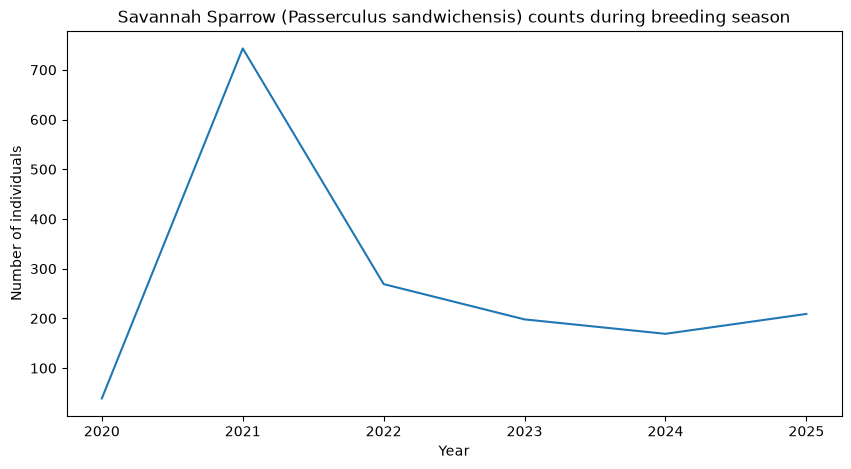

In [ ]:
(
    count_df
    .groupby("year")["individualCount"]
    .sum()  # or .mean()
    .plot(
        legend=False,
        xlabel="Year",
        ylabel="Number of individuals",
        figsize=(10, 5),
        title="Savannah Sparrow (Passerculus sandwichensis) individual counts"
    )
)
